# Partículas Auto-Propelidas

* PET - Física
* Petiano: Wallysson Pereira da Silva
* Data: 00/00/2026

$\quad$ Resumminho papapa

### Importando bibliotecas

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from itertools import combinations

### Informações sobre as bibliotecas

In [ ]:
%load_ext version_information
%version_information Matplotlib, Numpy

Software versions
Python 3.12.7 64bit [MSC v.1929 64 bit (AMD64)]
IPython 8.29.0
OS Windows 11 10.0.26200 SP0
Matplotlib 3.9.2
Numpy 2.1.3
Wed Aug 12 09:50:50 2026 Hora oficial do Brasil

## 1. Partículas Auto-Propelidas

## 2. Simulação

### 2.1 Trajetória de uma Partícula Auto-Propelida

In [3]:
N = 200
v_0 = 0.01
theta = 0
q = 0.15
pos = np.array([0,0], float)

posicoes = np.array([pos])


fig, ax = plt.subplots(figsize = (8,8))
ax.set_title(f'Evolução')
ax.plot(posicoes[:,0], posicoes[:,1], "ko")
ax.quiver(posicoes[:,0], posicoes[:,1], v_0*np.cos(theta), v_0*np.sin(theta), angles='xy', scale_units='xy',  color='red', label = "Velocidade.")
ax.grid()
d = 1
ax.set_xlim(-d,d)
ax.set_ylim(-d,d)


def update(frame):
    global pos, theta, q, posicoes, d
    ax.clear()

    ax.grid()
    ax.set_title(f'Trajetória de uma Partícula Auto-Propelida - {frame/N*100:.0f}%')

    theta = theta + np.random.normal(loc = 0, scale = q)
    pos[0] = pos[0] + v_0*np.cos(theta)
    pos[1] = pos[1] + v_0*np.sin(theta)
    ax.plot(pos[0], pos[1], "ko")
    ax.quiver(pos[0], pos[1], v_0*np.cos(theta),v_0*np.sin(theta), angles='xy', scale_units='xy',  color='red', label = "Velocidade.")
    
    posicoes = np.vstack((posicoes,pos))

    ax.plot(posicoes[:,0], posicoes[:,1], color = 'blue', linewidth = 1)


    if pos[0]>=d:
        ax.set_xlim(-2*d,2*d)
    else:
        ax.set_xlim(-d,d)


    if pos[1]>=d:
        ax.set_ylim(-2*d, 2*d)
    else:
        ax.set_ylim(-d,d)
    
    return 0

anim = FuncAnimation(fig, update, frames = N, interval = 80)

caminho = '../Imagens/Trajetoria.gif'
anim.save(caminho, writer = 'pillow', fps = 10)
plt.close(fig)

### 2.2 Múltiplas Partículas com Parede Periódica e Colisão Elástica

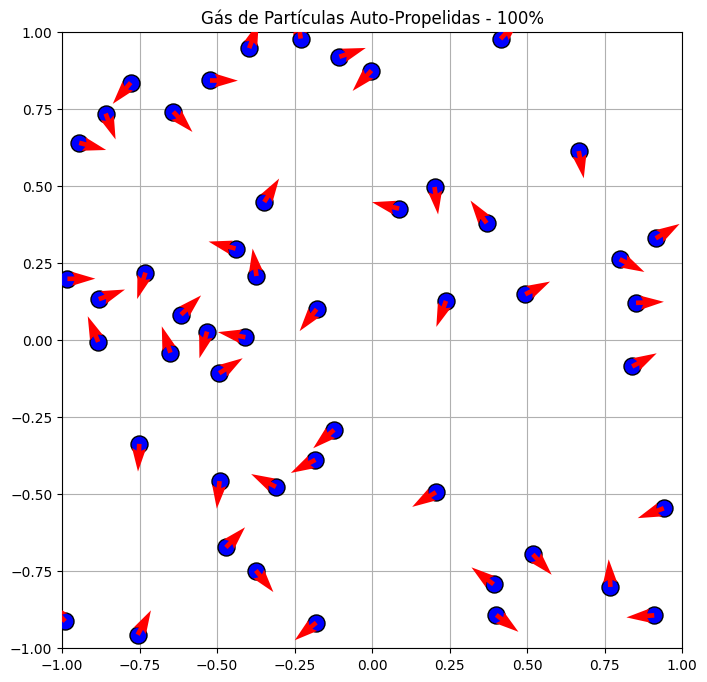

In [4]:
# Parâmetros da simulação
M = 50           # Número de partículas
N = 200          # Número de frames
v_0 = 0.03       # Velocidade constante escalar
q = 0.05          # Intensidade do ruído na orientação
R = 0.05         # Raio das partículas (para calcular colisões)
d = 1.0          # Limite do grid (-d até d)
arrow_scale = 3  # Fator para aumentar visualmente o tamanho da seta da velocidade

# Inicialização aleatória
pos = np.random.uniform(-d + R, d - R, (M, 2))
theta = np.random.uniform(0, 2 * np.pi, M)

# Configuração da Figura
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_xlim(-d, d)
ax.set_ylim(-d, d)
ax.grid()

# Elementos visuais
scatter = ax.scatter(pos[:, 0], pos[:, 1], s=150, c='blue', edgecolors='k', zorder=3)
quiver = ax.quiver(pos[:, 0], pos[:, 1], 
                   v_0 * np.cos(theta) * arrow_scale, 
                   v_0 * np.sin(theta) * arrow_scale, 
                   color='red', angles='xy', scale_units='xy', scale=1, zorder=4)

def update(frame):
    global pos, theta
    
    # 1. Atualizar ângulos com ruído e determinar vetores de velocidade
    theta += np.random.normal(loc=0, scale=q, size=M)
    V = np.column_stack((v_0 * np.cos(theta), v_0 * np.sin(theta)))
    
    # 2. Atualizar posições
    pos += V
    
    # 3. Condições de contorno periódicas (Pac-Man)
    # Envolve a posição de volta para o outro lado caso passe de -d ou d
    pos = np.mod(pos + d, 2 * d) - d

    # 4. Colisões Elásticas entre Partículas (Massa igual)
    for i, j in combinations(range(M), 2):
        vec_ij = pos[i] - pos[j]
        
        # Convenção da imagem mínima: corrige o vetor distância para a fronteira periódica
        vec_ij = vec_ij - 2 * d * np.round(vec_ij / (2 * d))
        
        dist = np.linalg.norm(vec_ij)
        
        # Checa se estão sobrepostas
        if dist < 2 * R and dist > 0:
            # Vetor normal à colisão
            n = vec_ij / dist
            
            # Velocidade relativa
            v_rel = V[i] - V[j]
            v_n = np.dot(v_rel, n)
            
            # Se v_n < 0, elas estão se aproximando e devem colidir
            if v_n < 0:
                # Troca de momento na direção normal
                V[i] = V[i] - v_n * n
                V[j] = V[j] + v_n * n
                
                # Reajustar o ângulo interno
                theta[i] = np.arctan2(V[i, 1], V[i, 0])
                theta[j] = np.arctan2(V[j, 1], V[j, 0])
                
            # Afastar fisicamente as partículas
            overlap = 2 * R - dist
            pos[i] += (overlap / 2) * n
            pos[j] -= (overlap / 2) * n

    # Garantir que o afastamento mecânico das colisões também respeite o contorno periódico
    pos = np.mod(pos + d, 2 * d) - d

    # 5. Atualizar os dados no gráfico
    scatter.set_offsets(pos)
    quiver.set_offsets(pos)
    # Multiplicamos o vetor visual da velocidade pelo arrow_scale
    quiver.set_UVC(v_0 * np.cos(theta) * arrow_scale, v_0 * np.sin(theta) * arrow_scale)
    
    ax.set_title(f'Gás de Partículas Auto-Propelidas - {frame/N*100:.0f}%')
    return scatter, quiver

# Geração da animação
anim = FuncAnimation(fig, update, frames=N, interval=50, blit=False)

caminho = '../Imagens/Multilplas_Particulas_PacMan.gif'
anim.save(caminho, writer='pillow', fps=20)
plt.show()

### 2.2 Múltiplas Partículas com Parede Periódica e Colisão Inelástica

In [5]:
# Parâmetros da simulação
M = 80           # Número de partículas
N = 500          # Número de frames (aumentado para observar a separação)
v_0 = 0.03       # Velocidade constante escalar
q = 0.01          # Intensidade do ruído na orientação
R = 0.05         # Raio das partículas
d = 1.0          # Limite do grid (-d até d)
arrow_scale = 3  # Fator para aumentar visualmente o tamanho da seta da velocidade

# Inicialização aleatória
pos = np.random.uniform(-d + R, d - R, (M, 2))
theta = np.random.uniform(0, 2 * np.pi, M)

# Configuração da Figura
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_xlim(-d, d)
ax.set_ylim(-d, d)
ax.grid()

# Elementos visuais
scatter = ax.scatter(pos[:, 0], pos[:, 1], s=150, c='blue', edgecolors='k', zorder=3)
quiver = ax.quiver(pos[:, 0], pos[:, 1], 
                   v_0 * np.cos(theta) * arrow_scale, 
                   v_0 * np.sin(theta) * arrow_scale, 
                   color='red', angles='xy', scale_units='xy', scale=1, zorder=4)

def update(frame):
    global pos, theta
    
    # 1. Atualizar ângulos com ruído e determinar vetores de velocidade
    # É aqui que partículas "grudadas" vão, aos poucos, perdendo o alinhamento
    theta += np.random.normal(loc=0, scale=q, size=M)
    V = np.column_stack((v_0 * np.cos(theta), v_0 * np.sin(theta)))
    
    # 2. Atualizar posições
    pos += V
    
    # 3. Condições de contorno periódicas (Pac-Man)
    pos = np.mod(pos + d, 2 * d) - d

    # 4. Colisões Inelásticas (Agrupamento / Alinhamento)
    for i, j in combinations(range(M), 2):
        vec_ij = pos[i] - pos[j]
        
        # Convenção da imagem mínima: corrige o vetor distância para a fronteira periódica
        vec_ij = vec_ij - 2 * d * np.round(vec_ij / (2 * d))
        dist = np.linalg.norm(vec_ij)
        
        # Checa se estão sobrepostas
        if dist < 2 * R and dist > 0:
            # Na colisão inelástica para partículas ativas, elas passam a compartilhar a mesma direção média
            V_avg = (V[i] + V[j]) / 2.0
            
            # Calcula o ângulo da velocidade combinada
            theta_novo = np.arctan2(V_avg[1], V_avg[0])
            
            # Força ambas as partículas a adotarem a mesma direção
            theta[i] = theta_novo
            theta[j] = theta_novo
            
            # Afastar fisicamente as partículas APENAS o suficiente para não ficarem 
            # num único ponto exato (elas continuarão coladas/tangentes)
            n = vec_ij / dist
            overlap = 2 * R - dist
            pos[i] += (overlap / 2) * n
            pos[j] -= (overlap / 2) * n

    # Garantir que o afastamento mecânico também respeite o contorno periódico
    pos = np.mod(pos + d, 2 * d) - d

    # 5. Atualizar os dados no gráfico
    scatter.set_offsets(pos)
    quiver.set_offsets(pos)
    quiver.set_UVC(v_0 * np.cos(theta) * arrow_scale, v_0 * np.sin(theta) * arrow_scale)
    
    ax.set_title(f'Gás de Partículas Auto-Propelidas - {frame/N*100:.0f}%')
    return scatter, quiver

# Geração da animação
anim = FuncAnimation(fig, update, frames=N, interval=50, blit=False)
caminho = '../Imagens/Colisao_inelastica.gif'
anim.save(caminho, writer='pillow', fps=20)
plt.close()

### 2.4 Múltiplas Partículas com Parede Periódica, Colisão Inelástica e Detecção

In [13]:
# Parâmetros da simulação
M = 50           # Número de partículas
N = 400          # Número de frames
v_0 = 0.03       # Velocidade constante escalar padrão
q = 0.1          # Intensidade do ruído na orientação padrão (aumentei levemente para dar contraste)
R = 0.05         # Raio das partículas
d = 1.0          # Limite do grid (-d até d)
arrow_scale = 3  # Fator para aumentar visualmente o tamanho da seta

# Novos Parâmetros de Detecção e Clustering
R_det = 4 * R    # Raio de detecção AGORA É MAIOR QUE 2*R (Campo de visão)
v_min = 0.008    # Velocidade mínima
q_min = 0.005    # Ruído mínimo (quase zero para manter o cluster perfeitamente alinhado)
alpha = 0.2      # Taxa de mudança suavizada

# Inicialização aleatória
pos = np.random.uniform(-d + R, d - R, (M, 2))
theta = np.random.uniform(0, 2 * np.pi, M)

# Variáveis de estado individuais
v_current = np.full(M, v_0)
q_current = np.full(M, q)

# Configuração da Figura
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_xlim(-d, d)
ax.set_ylim(-d, d)
ax.grid()

# Elementos visuais (Rápido = Azul, Lento = Vermelho)
norm = plt.Normalize(v_min, v_0)
scatter = ax.scatter(pos[:, 0], pos[:, 1], s=150, c=v_current, cmap='coolwarm_r', norm=norm, edgecolors='k', zorder=3)
quiver = ax.quiver(pos[:, 0], pos[:, 1], 
                   v_current * np.cos(theta) * arrow_scale, 
                   v_current * np.sin(theta) * arrow_scale, 
                   color='black', angles='xy', scale_units='xy', scale=1, zorder=4)

def update(frame):
    global pos, theta, v_current, q_current
    
    # 1. Definir alvos baseados na distância ATUAL
    v_target = np.full(M, v_0)
    q_target = np.full(M, q)
    
    # Varre todos os pares para verificar o range de detecção
    for i, j in combinations(range(M), 2):
        vec_ij = pos[i] - pos[j]
        # Imagem mínima (Pac-Man)
        vec_ij = vec_ij - 2 * d * np.round(vec_ij / (2 * d))
        dist = np.linalg.norm(vec_ij)
        
        # Se entraram no range de detecção, desaceleram e reduzem o ruído
        if dist < R_det:
            v_target[i] = v_min
            v_target[j] = v_min
            q_target[i] = q_min
            q_target[j] = q_min
            
    # 2. Relaxação: Atualiza gradativamente a velocidade e ruído reais em direção aos alvos
    v_current += alpha * (v_target - v_current)
    q_current += alpha * (q_target - q_current)
    
    # 3. Atualizar ângulos e gerar os vetores de velocidade
    theta += np.random.normal(loc=0, scale=q_current, size=M)
    V = np.column_stack((v_current * np.cos(theta), v_current * np.sin(theta)))
    
    # 4. Atualizar posições e aplicar contorno periódico
    pos += V
    pos = np.mod(pos + d, 2 * d) - d

    # 5. Colisões Inelásticas (quando tocam fisicamente: 2R)
    for i, j in combinations(range(M), 2):
        vec_ij = pos[i] - pos[j]
        vec_ij = vec_ij - 2 * d * np.round(vec_ij / (2 * d))
        dist = np.linalg.norm(vec_ij)
        
        # Checa se encostaram
        if dist < 2 * R and dist > 0:
            # Alinhamento inelástico: passam a compartilhar a mesma direção
            V_avg = (V[i] + V[j]) / 2.0
            theta_novo = np.arctan2(V_avg[1], V_avg[0])
            
            theta[i] = theta_novo
            theta[j] = theta_novo
            
            # Afastar fisicamente para não sobreporem, mas continuam coladas
            n = vec_ij / dist
            overlap = 2 * R - dist
            pos[i] += (overlap / 2) * n
            pos[j] -= (overlap / 2) * n

    # Reaplicar contorno após o afastamento
    pos = np.mod(pos + d, 2 * d) - d

    # 6. Atualizar os dados visuais no gráfico
    scatter.set_offsets(pos)
    scatter.set_array(v_current) # Cor baseada na velocidade
    quiver.set_offsets(pos)
    quiver.set_UVC(v_current * np.cos(theta) * arrow_scale, v_current * np.sin(theta) * arrow_scale)
    
    ax.set_title(f'Gás de Partículas Auto-Propelidas - {frame/N*100:.0f}%')
    return scatter, quiver

# Geração da animação
anim = FuncAnimation(fig, update, frames=N, interval=50, blit=False)

caminho = '../Imagens/Multilplas_Particulas_Deteccao.gif'
anim.save(caminho, writer='pillow', fps=20)
plt.close()

## 3. Conclusão

## Referências 

**[]** ....